In [1]:
import os, gc, json, zipfile, ssl
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from torchvision.models.feature_extraction import create_feature_extractor
import pywt
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from PIL import Image

# --- THE ULTIMATE SSL FIX FOR WINDOWS/ANACONDA ---
ssl._create_default_https_context = ssl._create_unverified_context
os.environ['CURL_CA_BUNDLE'] = ''
# -----------------------------------------------

# 1. --- DATASET UNZIPPING ---
def extract_dataset(zip_name):
    if os.path.exists(zip_name):
        folder_name = zip_name.replace('.zip', '')
        if not os.path.exists(folder_name):
            print(f"Extracting {zip_name}...")
            with zipfile.ZipFile(zip_name, 'r') as zip_ref:
                zip_ref.extractall('.')
            print(f"Finished extracting: {folder_name}")
        else:
            print(f"Folder '{folder_name}' already exists.")
    else:
        print(f"Error: {zip_name} not found!")

#extract_dataset('new-dataset-train.zip')
#extract_dataset('new-dataset-valid.zip')
extract_dataset('potato-test-dataset.zip')

# 2. --- PATH SETUP ---
#TRAIN_PATH = 'new-dataset-train'
#VAL_PATH   = 'new-dataset-valid'
TEST_PATH  = 'potato-test-dataset' 

# 3. --- SAVE DIRECTORY ---
SAVE_DIR = 'results-potato-test' 
os.makedirs(SAVE_DIR, exist_ok=True)

# 4. --- DEVICE SETUP ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"--- Environment Setup Complete ---")
print(f"Device: {DEVICE}")


Folder 'potato-test-dataset' already exists.
--- Environment Setup Complete ---
Device: cpu


In [2]:
class AdvancedDWTExtractor:
    def __init__(self, wavelet='db8', level=3):
        self.wavelet = wavelet
        self.level = level

    def denoise_coeffs(self, coeffs):
        new_coeffs = [coeffs[0]]
        for detail_level in coeffs[1:]:
            thresholded = []
            for d in detail_level:
                sigma = np.median(np.abs(d)) / 0.6745
                if sigma > 1e-6:
                    thresh = sigma * np.sqrt(2 * np.log(d.size + 1e-12))
                    thresholded.append(pywt.threshold(d, thresh, mode='soft'))
                else:
                    thresholded.append(d)
            new_coeffs.append(tuple(thresholded))
        return new_coeffs

    def get_stats(self, data):
        energy = np.sum(data**2) / (data.size + 1e-12)
        std = np.std(data)
        entropy = -np.sum(data**2 * np.log(data**2 + 1e-12)) / (data.size + 1e-12)
        return [energy, std, entropy]

    def __call__(self, img_gray):
        coeffs = pywt.wavedec2(img_gray, self.wavelet, level=self.level)
        coeffs = self.denoise_coeffs(coeffs)
        features = []
        features.extend(self.get_stats(coeffs[0]))
        for detail_level in coeffs[1:]:
            for band in detail_level:
                features.extend(self.get_stats(band))
        return torch.tensor(features).float()

class DWTTransform:
    def __init__(self, wavelet='db8', size=(224,224)):
        self.extractor = AdvancedDWTExtractor(wavelet=wavelet, level=3)
        self.size = size

    def __call__(self, img):
        img_gray = np.array(img.resize(self.size).convert('L')) / 255.0
        return self.extractor(img_gray)


In [3]:
class HybridModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        
        # We wrap this in a try-except block
        try:
            print("Attempting to load pre-trained MobileNetV2 weights...")
            mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
            print("Successfully loaded pre-trained weights.")
        except Exception as e:
            print(f"Internet connection failed. Initializing with RANDOM weights.")
            # weights=None means it won't try to download anything
            mobilenet = models.mobilenet_v2(weights=None) 

        self.spatial_extractor = create_feature_extractor(
            mobilenet, return_nodes={'features.18': 'feat'}
        )

        self.refine = ConvBNReLU(1280, 1280, kernel_size=1)
        self.se = SEBlock(1280)

        self.freq_mlp = nn.Sequential(
            nn.Linear(30, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True)
        )

        self.fusion = nn.Sequential(
            nn.Linear(1280 + 256, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3)
        )
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, img, dwt):
        spatial = self.spatial_extractor(img)['feat']
        spatial = self.refine(spatial)
        spatial = self.se(spatial)
        spatial = spatial.mean(dim=(2,3))

        freq = self.freq_mlp(dwt)
        fused = torch.cat([spatial, freq], dim=1)
        return self.classifier(self.fusion(fused))


In [4]:
class CustomDataset(Dataset):
    def __init__(self, folder_path):
        self.dataset = datasets.ImageFolder(folder_path)
        self.classes = self.dataset.classes
        self.rgb_transform = transforms.Compose([
            transforms.Resize((224,224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
        ])
        self.dwt_transform = DWTTransform()

    def __len__(self): return len(self.dataset)
    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        return self.rgb_transform(img), self.dwt_transform(img), label

# Initialize datasets
#train_dataset = CustomDataset(TRAIN_PATH)
#val_dataset   = CustomDataset(VAL_PATH)
test_dataset  = CustomDataset(TEST_PATH)

# CHANGE: num_workers=0 is much more stable on local Windows Jupyter
#train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
#val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

print(f"Classes found: {test_dataset.classes}")


Classes found: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


Mapped local classes ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy'] to model indices [12, 13, 14]


Testing potato Data: 100%|██████████| 7/7 [00:05<00:00,  1.29it/s]



--- Potato Test Dataset Report ---
                       precision    recall  f1-score   support

Potato___Early_blight       1.00      0.88      0.94       100
 Potato___Late_blight       1.00      1.00      1.00       100
     Potato___healthy       1.00      1.00      1.00        16

            micro avg       1.00      0.94      0.97       216
            macro avg       1.00      0.96      0.98       216
         weighted avg       1.00      0.94      0.97       216



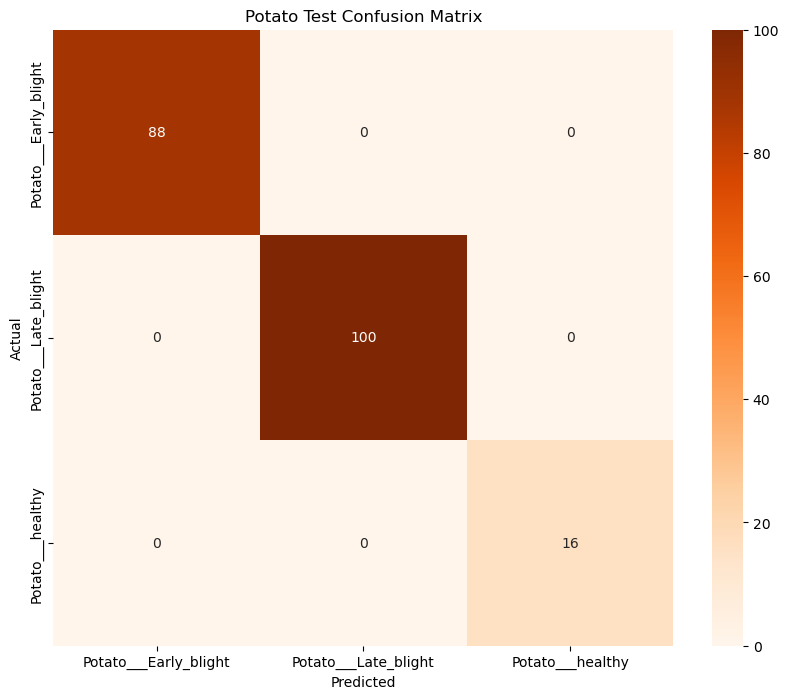

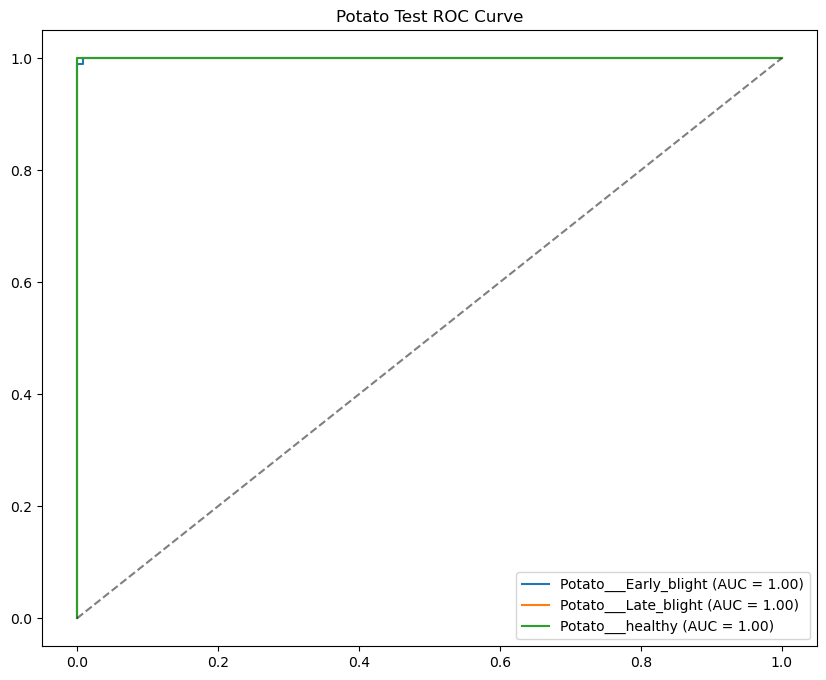

In [5]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision import models, transforms, datasets
from torchvision.models.feature_extraction import create_feature_extractor
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import pywt
from PIL import Image

# 1. --- BLUEPRINTS ---
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )
    def forward(self, x):
        b, c, _, _ = x.size()
        y = x.mean(dim=(2,3))
        y = self.fc(y).view(b, c, 1, 1)
        return x * y

class ConvBNReLU(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size, padding=kernel_size//2, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.block(x)

class HybridModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        mobilenet = models.mobilenet_v2(weights=None) 
        self.spatial_extractor = create_feature_extractor(mobilenet, return_nodes={'features.18': 'feat'})
        self.refine = ConvBNReLU(1280, 1280, kernel_size=1)
        self.se = SEBlock(1280)
        self.freq_mlp = nn.Sequential(
            nn.Linear(30, 128), nn.BatchNorm1d(128), nn.ReLU(inplace=True),
            nn.Linear(128, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True)
        )
        self.fusion = nn.Sequential(
            nn.Linear(1280 + 256, 512), nn.BatchNorm1d(512), nn.ReLU(inplace=True), nn.Dropout(0.3)
        )
        self.classifier = nn.Linear(512, num_classes)

    def forward(self, img, dwt):
        spatial = self.spatial_extractor(img)['feat']
        spatial = self.refine(spatial)
        spatial = self.se(spatial)
        spatial = spatial.mean(dim=(2,3))
        freq = self.freq_mlp(dwt)
        fused = torch.cat([spatial, freq], dim=1)
        return self.classifier(self.fusion(fused))

# 2. --- SETUP ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TRAINED_MODEL_PATH = os.path.join('results', 'best_plant_model.pth') 
NEW_RESULTS_DIR = 'results-potato-test'
os.makedirs(NEW_RESULTS_DIR, exist_ok=True)

# 3. --- LOAD MODEL & CREATE CLASS MAPPING ---
checkpoint = torch.load(TRAINED_MODEL_PATH, map_location=DEVICE)
model_classes = checkpoint['classes'] # The original 38 class names
model = HybridModel(len(model_classes)).to(DEVICE)
model.load_state_dict(checkpoint['model_state'])
model.eval()

# Map your 4 local apple folders to the model's global indices
# We look for names like 'Apple___Apple_scab' in the model's memory
apple_indices = []
for local_name in test_dataset.classes:
    # Logic to find the matching global name (handles different naming styles)
    match = [i for i, name in enumerate(model_classes) if local_name.lower() in name.lower()]
    if match:
        apple_indices.append(match[0])
    else:
        print(f"Warning: Could not find a match for {local_name} in model memory.")

print(f"Mapped local classes {test_dataset.classes} to model indices {apple_indices}")

# 4. --- RUN TESTING ---
y_true_global, y_pred_global, y_probs = [], [], []

with torch.no_grad():
    for img, dwt, labels in tqdm(test_loader, desc="Testing potato Data"):
        img, dwt, labels = img.to(DEVICE), dwt.to(DEVICE), labels.to(DEVICE)
        outputs = model(img, dwt)
        
        # Convert local label (0-3) to model label (e.g. 7, 8, 9, 10)
        current_labels_global = [apple_indices[l] for l in labels.cpu().numpy()]
        
        y_probs.extend(torch.softmax(outputs, dim=1).cpu().numpy())
        y_true_global.extend(current_labels_global)
        y_pred_global.extend(outputs.max(1)[1].cpu().numpy())

# 5. --- RESULTS (Filtered to only show the 4 Apple classes) ---
# We tell the report to ONLY look at the indices we mapped
print("\n--- Potato Test Dataset Report ---")
print(classification_report(y_true_global, y_pred_global, 
                            labels=apple_indices, 
                            target_names=test_dataset.classes))

# 6. --- CONFUSION MATRIX ---
cm = confusion_matrix(y_true_global, y_pred_global, labels=apple_indices)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=test_dataset.classes, yticklabels=test_dataset.classes)
plt.title('Potato Test Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig(os.path.join(NEW_RESULTS_DIR, 'Potato_confusion_matrix.png'))
plt.show()

# 7. --- ROC CURVE ---
y_true_bin = label_binarize(y_true_global, classes=range(len(model_classes)))
plt.figure(figsize=(10, 8))
for i, global_idx in enumerate(apple_indices):
    fpr, tpr, _ = roc_curve(y_true_bin[:, global_idx], np.array(y_probs)[:, global_idx])
    plt.plot(fpr, tpr, label=f'{test_dataset.classes[i]} (AUC = {auc(fpr, tpr):.2f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.legend(loc='lower right')
plt.title('Potato Test ROC Curve')
plt.savefig(os.path.join(NEW_RESULTS_DIR, 'Potato_roc_curve.png'))
plt.show()

In [6]:
from sklearn.metrics import accuracy_score

# 1. Calculate the overall accuracy
# This compares the global index of the ground truth vs the predicted global index
overall_test_acc = accuracy_score(y_true_global, y_pred_global)

# 2. Detailed count for clarity
total_samples = len(y_true_global)
correct_count = sum(np.array(y_true_global) == np.array(y_pred_global))
wrong_count = total_samples - correct_count

# 3. Print the results
print("-" * 40)
print("      Potato DATASET TEST SUMMARY")
print("-" * 40)
print(f"Total Apple Images Tested:  {total_samples}")
print(f"Correctly Identified:       {correct_count}")
print(f"Incorrectly Identified:     {wrong_count}")
print("-" * 40)
print(f"OVERALL TEST ACCURACY:      {overall_test_acc*100:.2f}%")
print("-" * 40)

# 4. Save results to a text file in the results-apple-test folder
summary_path = os.path.join(NEW_RESULTS_DIR, 'apple_accuracy_summary.txt')
with open(summary_path, 'w') as f:
    f.write("--- POTATO TEST DATASET RESULTS ---\n")
    f.write(f"Total Images: {total_samples}\n")
    f.write(f"Correct:      {correct_count}\n")
    f.write(f"Accuracy:     {overall_test_acc*100:.2f}%\n")

print(f"Summary saved to: {summary_path}")

----------------------------------------
      Potato DATASET TEST SUMMARY
----------------------------------------
Total Apple Images Tested:  216
Correctly Identified:       204
Incorrectly Identified:     12
----------------------------------------
OVERALL TEST ACCURACY:      94.44%
----------------------------------------
Summary saved to: results-potato-test\apple_accuracy_summary.txt
